# XGBoost on TF-IDF

This notebook trains an XGBoost model on the same TF-IDF features and train/test split as the Logistic Regression baseline. A boosted model of 200 trees cannot be read directly, so we explain it with post-hoc methods.

The explanation steps follow the course's interpretation pipeline: global importance (PFI / TreeSHAP) → feature effects (PDP) → heterogeneity (ICE / centered ICE) → individual decisions (LIME / SHAP).

## 1. Setup

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import nltk
nltk.download("stopwords")
nltk.download("wordnet")
nltk.download("punkt")
nltk.download("punkt_tab")

from IPython.display import display
from xgboost import XGBClassifier
from sklearn.metrics import (
    classification_report, confusion_matrix,
    ConfusionMatrixDisplay, recall_score, accuracy_score, roc_auc_score
)
from sklearn.inspection import PartialDependenceDisplay

from lime.lime_text import LimeTextExplainer
from lime.submodular_pick import SubmodularPick
import shap

from preprocessing import (
    preprocess_text, get_tfidf_features,
    get_train_test_split, select_top_k_terms, get_split_tfidf, RANDOM_STATE
)

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\ADMIN\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to
[nltk_data]     C:\Users\ADMIN\AppData\Roaming\nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\ADMIN\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\ADMIN\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
c:\Users\ADMIN\Desktop\XDS_project\env\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 2. Load Cleaned Dataset

In [2]:
df = pd.read_csv("Dataset/fake_news_dataset_cleaned.csv")
df[["title", "text", "label", "label_encoded"]].head()

,title,text,label,label_encoded
0,Foreign Democrat final.,more tax development both store agreement lawy...,real,0
1,To offer down resource great point.,probably guess western behind likely next inve...,fake,1
2,Himself church myself carry.,them identify forward present success risk sev...,fake,1
3,You unit its should.,phone which item yard Republican safe where po...,fake,1
4,Billion believe employee summer how.,wonder myself fact difficult course forget exa...,fake,1


## 3. Text Preprocessing (NLP Pipeline)

In [3]:
df["full_text"] = df["title"] + " " + df["text"]
df["processed_text"] = df["full_text"].apply(preprocess_text)
df[["full_text", "processed_text"]].head()

,full_text,processed_text
0,Foreign Democrat final. more tax development b...,foreign democrat final tax development store a...
1,To offer down resource great point. probably g...,offer resource great point probably guess west...
2,Himself church myself carry. them identify for...,church carry identify forward present success ...
3,You unit its should. phone which item yard Rep...,unit phone item yard republican safe police id...
4,Billion believe employee summer how. wonder my...,billion believe employee summer wonder fact di...


Quick sanity check: compare one raw vs. processed example side by side.

In [4]:
print("RAW:\n", df["full_text"].iloc[0][:300])
print("\nPROCESSED:\n", df["processed_text"].iloc[0][:300])

RAW:
 Foreign Democrat final. more tax development both store agreement lawyer hear outside continue reach difference yeah figure your power fear identify there protect security great national nothing fast story why late nearly bit cost tough since question to power almost future young conference behind a

PROCESSED:
 foreign democrat final tax development store agreement lawyer hear outside continue reach difference yeah figure power fear identify protect security great national nothing fast story late nearly bit cost tough since question power almost future young conference behind ahead building teach million b


## 4. TF-IDF Vectorization

In [5]:
X, y, tfidf = get_tfidf_features(df)

print("TF-IDF matrix shape:", X.shape)

TF-IDF matrix shape: (20000, 867)


## 5. Train/Test Split

In [6]:
X_train, X_test, y_train, y_test, tfidf = get_split_tfidf(df)
feature_names = tfidf.get_feature_names_out()

print("Train shape:", X_train.shape)
print("Test shape:", X_test.shape)
print("\nTrain class balance:\n", y_train.value_counts(normalize=True).round(3))
print("\nTest class balance:\n", y_test.value_counts(normalize=True).round(3))

Train shape: (16000, 867)
Test shape: (4000, 867)

Train class balance:
 label_encoded
1    0.503
0    0.497
Name: proportion, dtype: float64

Test class balance:
 label_encoded
1    0.503
0    0.497
Name: proportion, dtype: float64


### 5.1 Dense Arrays for XGBoost

XGBoost treats the zeros in a sparse matrix as missing values, so the same article can get a different prediction depending on whether it is passed in sparse or dense form. To keep training, evaluation and every explanation consistent, the TF-IDF matrix is converted to a dense array here and the dense version is used from now on.

In [7]:
X_train_dense = X_train.toarray().astype(np.float32)
X_test_dense = X_test.toarray().astype(np.float32)

## 6. Train XGBoost

XGBoost builds trees one after another, each fixing the mistakes of the trees before it. We keep the trees small (depth 4, minimum leaf weight 10) and the learning rate low, so the model memorizes less of the training data and is quick to explain with TreeSHAP.

In [8]:
xgb_model = XGBClassifier(
    n_estimators=200,
    learning_rate=0.05,
    max_depth=4,
    min_child_weight=10,
    tree_method="hist",
    eval_metric="logloss",
    random_state=RANDOM_STATE,
    n_jobs=-1
)
xgb_model.fit(X_train_dense, y_train)
y_pred = xgb_model.predict(X_test_dense)

## 7. Validate Predictive Performance

In [9]:
print(classification_report(y_test, y_pred, target_names=["real", "fake"]))

recall_fake = recall_score(y_test, y_pred, pos_label=1)
accuracy = accuracy_score(y_test, y_pred)
train_recall = recall_score(y_train, xgb_model.predict(X_train_dense), pos_label=1)
auc = roc_auc_score(y_test, xgb_model.predict_proba(X_test_dense)[:, 1])

print(f"Fake-class recall (test):  {recall_fake:.4f}")
print(f"Fake-class recall (train): {train_recall:.4f}   <- large gap vs test = overfitting")
print(f"Accuracy (test): {accuracy:.4f}")
print(f"ROC AUC (test): {auc:.4f}")
print(f"Share of test articles predicted fake: {y_pred.mean():.3f}")

              precision    recall  f1-score   support

        real       0.51      0.49      0.50      1989
        fake       0.51      0.53      0.52      2011

    accuracy                           0.51      4000
   macro avg       0.51      0.51      0.51      4000
weighted avg       0.51      0.51      0.51      4000

Fake-class recall (test):  0.5281
Fake-class recall (train): 0.7817   <- large gap vs test = overfitting
Accuracy (test): 0.5110
ROC AUC (test): 0.5104
Share of test articles predicted fake: 0.517


XGBoost catches 52.8% of fake articles (recall = 0.5281) and is right 51.3% of the time it says fake, barely above the 50.3% share of fake articles in the test set. Accuracy (0.5110) is less than one point above what a model calling every article fake would get, and ROC AUC (0.5104) is close to 0.5, so the model barely separates fake from real.

The model labels 51.7% of articles as fake, and its recall (52.8%) is only about one point higher. So it catches fake articles at about the rate you would get by flagging half the articles at random.

Training recall is 0.7817 against 0.5281 on test, so even with small trees the model fits the training articles much better than new ones. Compared with the baseline (recall 0.5162), it catches 24 more fake articles. That’s the highest recall of any model so far, but at 51.1%, its accuracy is no better than LightGBM’s or the Random Forest’s (both 51.2%).

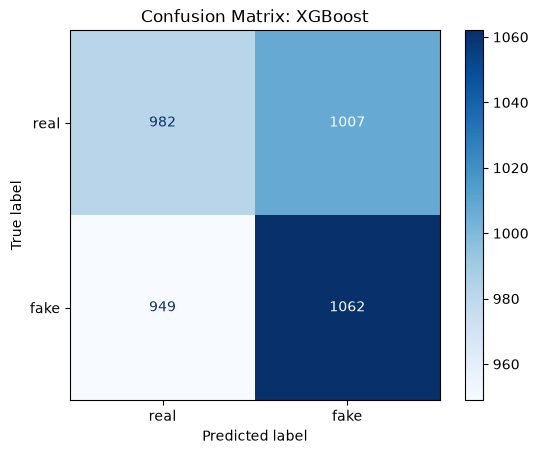

In [10]:
cm = confusion_matrix(y_test, y_pred)
ConfusionMatrixDisplay(cm, display_labels=["real", "fake"]).plot(cmap="Blues")
plt.title("Confusion Matrix: XGBoost")
plt.show()

- True Positive, correctly caught fake article: 1,062
- False Negative, fake article predicted as real: 949
- False Positive, real article predicted as fake: 1,007
- True Negative, correctly identified real article: 982

The four cells are almost equal, so the model is wrong about as often as it is right in both classes. It misses 964 fake articles (48%) and flags 982 real ones (49%). For a trust-and-safety reviewer, this means 2,029 articles sent for checking, of which only 1,047 are fake. Half the reviewer's time goes to real articles, while almost half the fake ones are never flagged. It raises fewer false alarms than the baseline (982 vs 1,036), but this does not make it reliable.

The four cells are almost equal, so the model is wrong about as often as it is right in both classes. It misses 949 fake articles (47%) and flags 1,007 real ones (51%). For a trust-and-safety reviewer, this means 2,069 articles sent for checking, of which only 1,062 are fake. Half the reviewer’s time goes to real articles, while almost half the fake ones are never flagged. It misses fewer fakes (949 vs 973) and raises fewer false alarms (1,007 vs 1,035) than the baseline, but on a single test split, gains this small are within normal variation.

## 8. Top-K Terms and Multicollinearity Check

With 867 terms, inspecting every term is impractical: PDP and ICE would need hundreds of plots, and an 867 × 867 correlation matrix cannot be read. We therefore focus on the 30 terms most linked to the fake/real label (K = 30), ranked by a chi-squared score on the training data only.

Chi-squared measures how unevenly a term's weight is split between fake and real articles. A higher score means a stronger link to the label, but it does not show the direction. We use it because it does not depend on any model, so every notebook can share the same list. Since TF-IDF weights are not counts, the scores are used only for ranking, not as significance tests.

In [11]:
K = 30
top_idx, top_terms, top_scores = select_top_k_terms(X_train, y_train, feature_names, k=K, method="chi2")
pd.DataFrame({"term": top_terms, "chi2_score": top_scores}).head(7)

,term,chi2_score
0,economy,0.576968
1,particular,0.552170
2,significant,0.532851
3,model,0.517423
4,bring,0.503194
5,girl,0.502465
6,reflect,0.500119


The top seven terms (economy, particular, significant, model, girl, bring, reflect) are ordinary words, not sensational language. Their scores are low and close together (0.50 to 0.58), so no term stands out.

All 30 terms are used below, but tables and plots show only 7 at a time, since people can hold about 7 ± 2 items in working memory.

In [12]:
rng = np.random.RandomState(RANDOM_STATE)
sample_idx = rng.choice(X_test_dense.shape[0], size=500, replace=False)
X_sample = X_test_dense[sample_idx]          # 500-row sample for PDP/ICE and SHAP

The heatmap shows how strongly the weights of each pair of top terms move together, from −1 (one rises when the other falls) to 1 (they rise together). This matters for two methods: PFI can split importance between related terms, and PDP changes one term while holding the others fixed, which only gives realistic articles if the terms are not related.

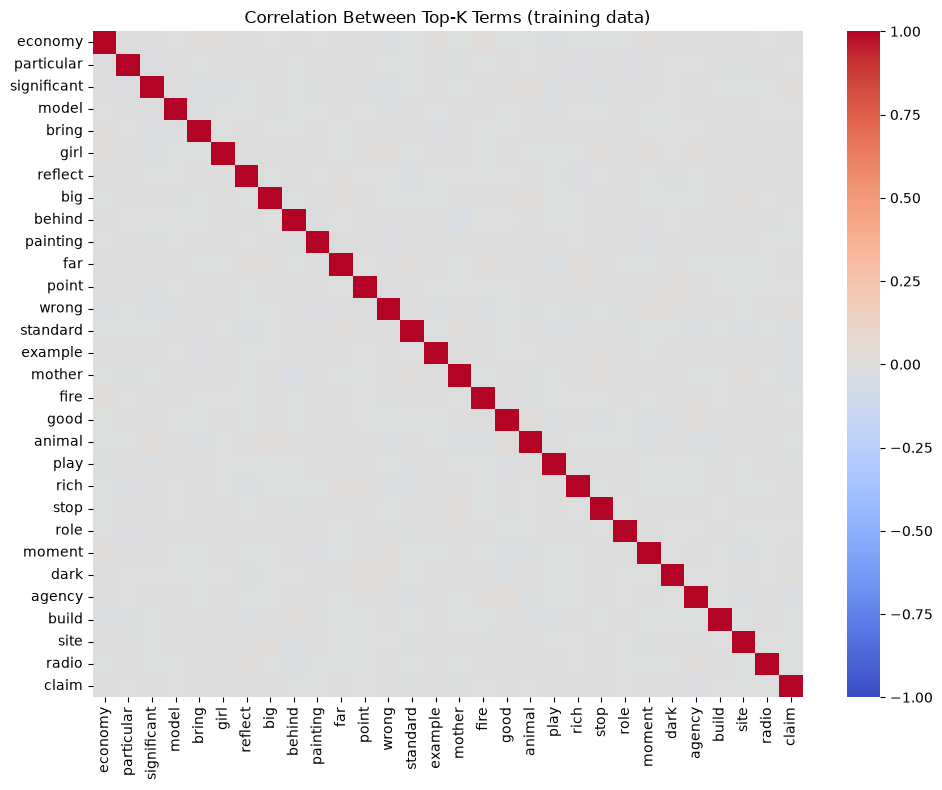

No pairs of terms with |correlation| > 0.5


In [13]:
X_train_topk = pd.DataFrame(X_train[:, top_idx].toarray(), columns=top_terms)
corr = X_train_topk.corr()

plt.figure(figsize=(10, 8))
sns.heatmap(corr, cmap="coolwarm", center=0, vmin=-1, vmax=1)
plt.title("Correlation Between Top-K Terms (training data)")
plt.tight_layout()
plt.show()

pairs = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack()
high_pairs = pairs[pairs.abs() > 0.5]
if high_pairs.empty:
    print("No pairs of terms with |correlation| > 0.5")
else:
    print("Pairs with |correlation| > 0.5:")
    print(high_pairs.sort_values(key=abs, ascending=False))

Apart from the diagonal, where each term is compared with itself, every cell is pale gray, meaning a correlation close to 0, and no pair goes above 0.5. The top terms are close to independent, so we use PDP rather than ALE, and PFI should not be splitting importance between related terms. The check only covers the top 30 terms and linear relationships, so it does not rule out every dependence.

## 9. Global Importance (PFI and TreeSHAP)

### 9.1 Permutation Feature Importance (PFI)

Each of the 30 top terms is shuffled across the test articles, and we measure how much Fake-class recall drops, averaged over 5 repeats. A large drop means the model relies on that term to catch fake articles. A drop near zero means it barely matters.

In [14]:
def permutation_recall_drop(model, X_dense, y_true, col_indices, n_repeats=5, seed=RANDOM_STATE):
    rng = np.random.RandomState(seed)
    base = recall_score(y_true, model.predict(X_dense), pos_label=1)
    rows = []
    for col in col_indices:
        original = X_dense[:, col].copy()
        drops = []
        for _ in range(n_repeats):
            X_dense[:, col] = rng.permutation(original)
            drops.append(base - recall_score(y_true, model.predict(X_dense), pos_label=1))
        X_dense[:, col] = original
        rows.append((feature_names[col], np.mean(drops), np.std(drops)))
    result = pd.DataFrame(rows, columns=["term", "mean_recall_drop", "std"])
    return base, result.sort_values("mean_recall_drop", ascending=False)

base_recall, pfi_df = permutation_recall_drop(xgb_model, X_test_dense, y_test, top_idx)
print(f"Recall before shuffling: {base_recall:.4f}")
pfi_df.head(7)

Recall before shuffling: 0.5281


,term,mean_recall_drop,std
22,role,0.005669,0.001281
5,girl,0.005271,0.001024
9,painting,0.005172,0.003123
29,claim,0.004873,0.001014
0,economy,0.004078,0.002694
19,play,0.003680,0.002960
1,particular,0.003481,0.006453


All drops are small. The largest, for role, is 0.0057, about 11 of the 2,011 fake test articles. The smallest shown, for particular, is 0.0035, about 7 articles.

role, girl and claim are the most consistent: their drops are more than four times their standard deviations. painting, economy and play vary more between repeats (about 1.2 to 1.7 standard deviations), and for particular the standard deviation is larger than the drop itself, so its effect is uncertain.

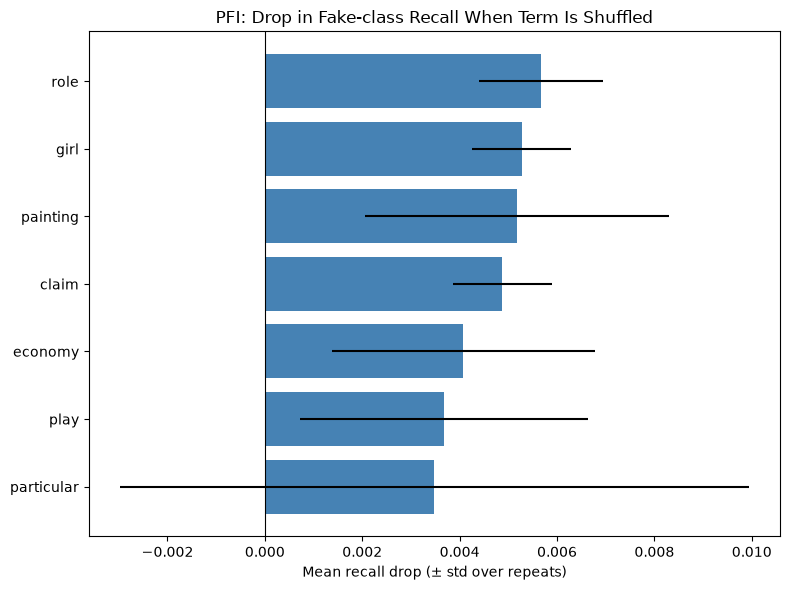

In [15]:
top_pfi = pfi_df.head(7).iloc[::-1]
plt.figure(figsize=(8, 6))
plt.barh(top_pfi["term"], top_pfi["mean_recall_drop"], xerr=top_pfi["std"], color="steelblue")
plt.axvline(0, color="black", linewidth=0.8)
plt.title("PFI: Drop in Fake-class Recall When Term Is Shuffled")
plt.xlabel("Mean recall drop (± std over repeats)")
plt.tight_layout()
plt.show()

Only particular’s error bar crosses zero. role, girl and claim have narrow bars that stay well above it. The bars overlap heavily, so the exact order should not be read closely. The check below tests whether these drops are larger than chance.

#### Is PFI measuring anything?

As a check, we shuffle 30 random terms from outside the top 30. If their drops are as large as those of the top terms, the PFI ranking cannot be told apart from noise.

In [16]:
rng_null = np.random.RandomState(RANDOM_STATE)
other_idx = rng_null.choice(np.setdiff1d(np.arange(len(feature_names)), top_idx), 30, replace=False)
_, pfi_null = permutation_recall_drop(xgb_model, X_test_dense, y_test, other_idx)
print(pfi_null["mean_recall_drop"].describe())

count    30.000000
mean      0.000245
std       0.001260
min      -0.001392
25%      -0.000199
50%       0.000000
75%       0.000448
max       0.005172
Name: mean_recall_drop, dtype: float64


The 30 random terms mostly barely matter: their median drop is exactly zero, probably because XGBoost never uses many of them. But one random term drops recall by 0.0052, as much as painting.

Only role (0.0057) and girl (0.0053) drop recall by more than any random term, and only just. painting ties with the largest random term, and claim, economy, play and particular fall within the random range. So for XGBoost, PFI can barely tell its top terms apart from noise, and only role and girl show an effect that is plausibly real.

### 9.2 TreeSHAP (global view)

SHAP splits each prediction into a contribution from each term, starting from the model's average output. TreeSHAP calculates these values exactly for tree models. They are computed for the same 200 test articles as in the other notebooks and then averaged.

For XGBoost, SHAP values are in log-odds, not probability. Positive values push toward fake and negative values toward real. Near a probability of 0.5, a change of 0.1 in log-odds is about 2.5 percentage points.

In [17]:
explainer_shap = shap.TreeExplainer(xgb_model)
X_shap = X_sample[:200]

sv = explainer_shap.shap_values(X_shap, check_additivity=False)

# SHAP's output format differs by version; extract values for the FAKE class (index 1)
if isinstance(sv, list):
    sv_fake = sv[1]
elif sv.ndim == 3:
    sv_fake = sv[:, :, 1]
else:
    sv_fake = sv

ev = explainer_shap.expected_value
base_value = ev[1] if np.ndim(ev) > 0 else ev
print("SHAP values shape:", sv_fake.shape)

SHAP values shape: (200, 867)


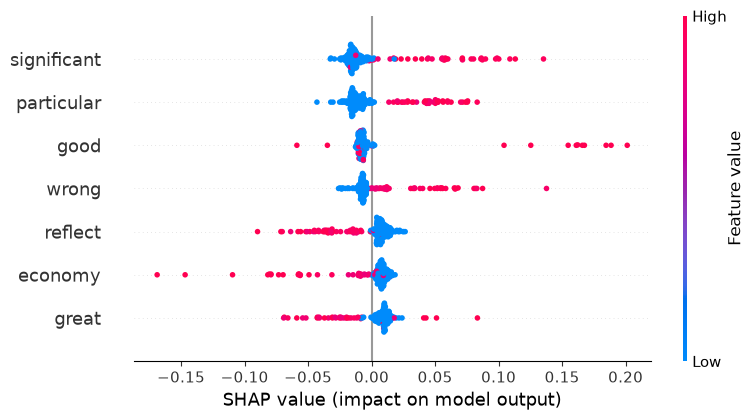

In [18]:
shap.summary_plot(sv_fake, X_shap, feature_names=list(feature_names), max_display=7)

Each dot is one article. Its position shows how much a term pushed the output toward fake (right) or real (left), and its color shows the term's weight: red for high, blue for low or absent.

Most dots are blue and near zero, since most articles don't contain a given term. The red dots carry the effect: significant, particular, good and wrong push toward fake, while reflect, economy and great push toward real. good and great each have a couple of articles going the other way.

The largest single push is about 0.20 log-odds (good), roughly 5 percentage points. On average, significant moves the output by 0.022 log-odds, about 0.6 percentage points, and the other six terms are close behind. Six of the seven terms also appear in the baseline’s top lists, all with the same direction. great is the exception, as it wasn’t among the baseline’s top terms.

Six of the seven SHAP terms are among the 30 that PFI tested (great is not), but only economy and particular appear in both top-seven lists. The two methods measure different things. SHAP measures how much a term moves the output on average across all articles, while PFI measures how much catching fake articles suffers when the term is shuffled. significant moves the output most but has no clear effect on recall, so it changes the model’s confidence more than its decisions.

In [19]:
shap_importance = pd.DataFrame({
    "term": feature_names,
    "mean_abs_shap": np.abs(sv_fake).mean(axis=0)
}).sort_values("mean_abs_shap", ascending=False)

shap_importance.head(7)

,term,mean_abs_shap
683,significant,0.022318
528,particular,0.019501
316,good,0.015826
860,wrong,0.014576
618,reflect,0.014481
220,economy,0.014066
318,great,0.013743


## 10. Feature Effects (PDP)

PDP shows the model's average predicted probability of fake as one term's weight increases, so it shows which direction a term pushes and how strongly. Because the top terms are not correlated, we use PDP rather than ALE. The six terms with the highest chi-squared scores are plotted.

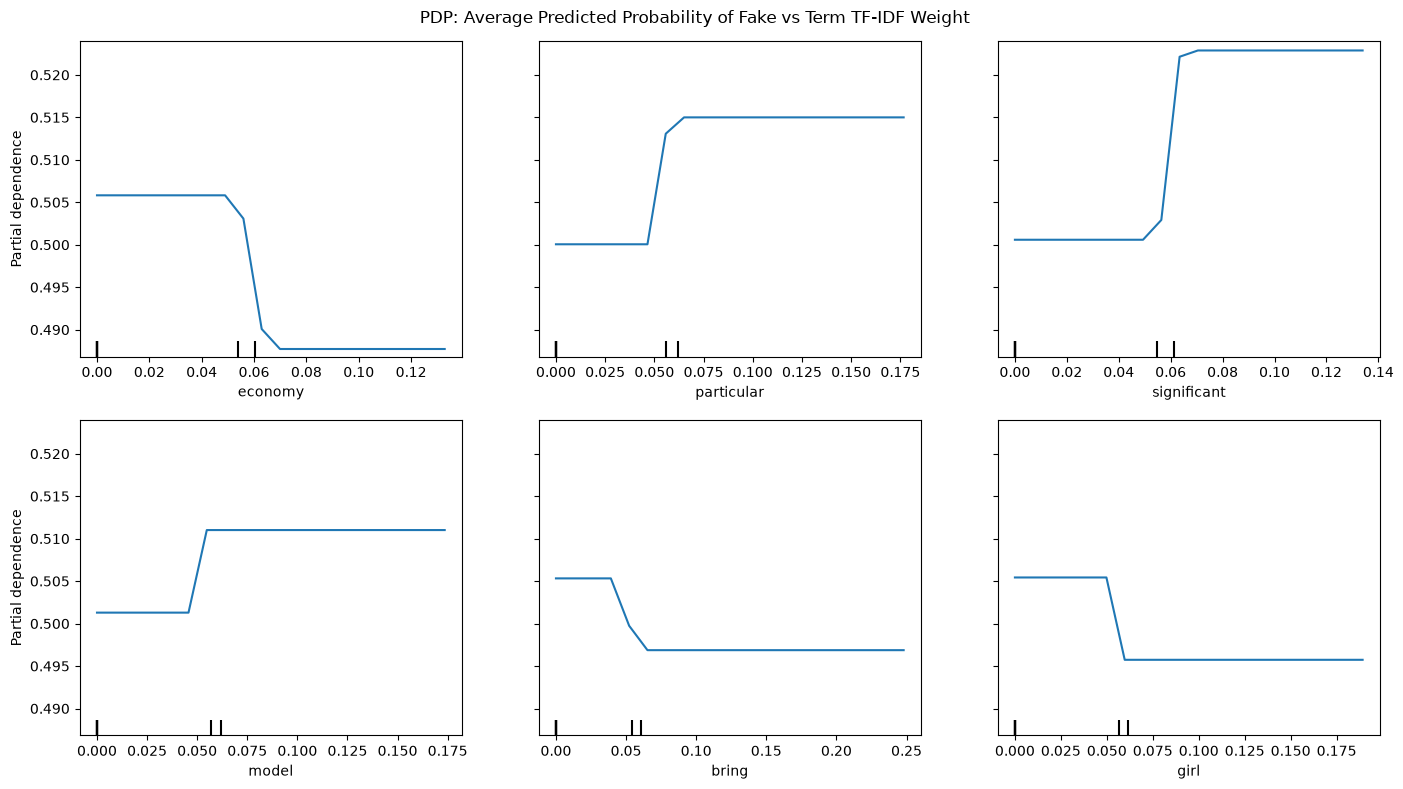

In [20]:
pdp_idx = list(top_idx[:6])

pdp_display = PartialDependenceDisplay.from_estimator(
    xgb_model, X_sample,
    features=pdp_idx,
    feature_names=list(feature_names),
    kind="average",
    grid_resolution=20,
    percentiles=(0, 1),       # TF-IDF is mostly zeros, so the default 5-95% range would collapse to a single value
    n_cols=3,
    random_state=RANDOM_STATE,
)
pdp_display.figure_.set_size_inches(14, 8)
pdp_display.figure_.suptitle("PDP: Average Predicted Probability of Fake vs Term TF-IDF Weight")
plt.tight_layout()
plt.show()

Each curve is a step: flat, a jump around a weight of 0.05, then flat again. A term is either absent (weight 0) or present at about 0.055 or more, so the step is simply the difference between containing the word and not. Weights in between never occur in real articles.

particular, significant and model raise the probability of fake, and economy, girl and bring lower it. These directions match SHAP and the baseline.

The largest steps are for significant (0.501 to 0.523) and economy (0.506 to 0.488), about 2 percentage points each. particular moves about 1.5 points, and model, girl and bring about 1 point each.

## 11. Heterogeneity (ICE)

ICE draws one line per article instead of only the average, showing whether a term affects every article the same way.

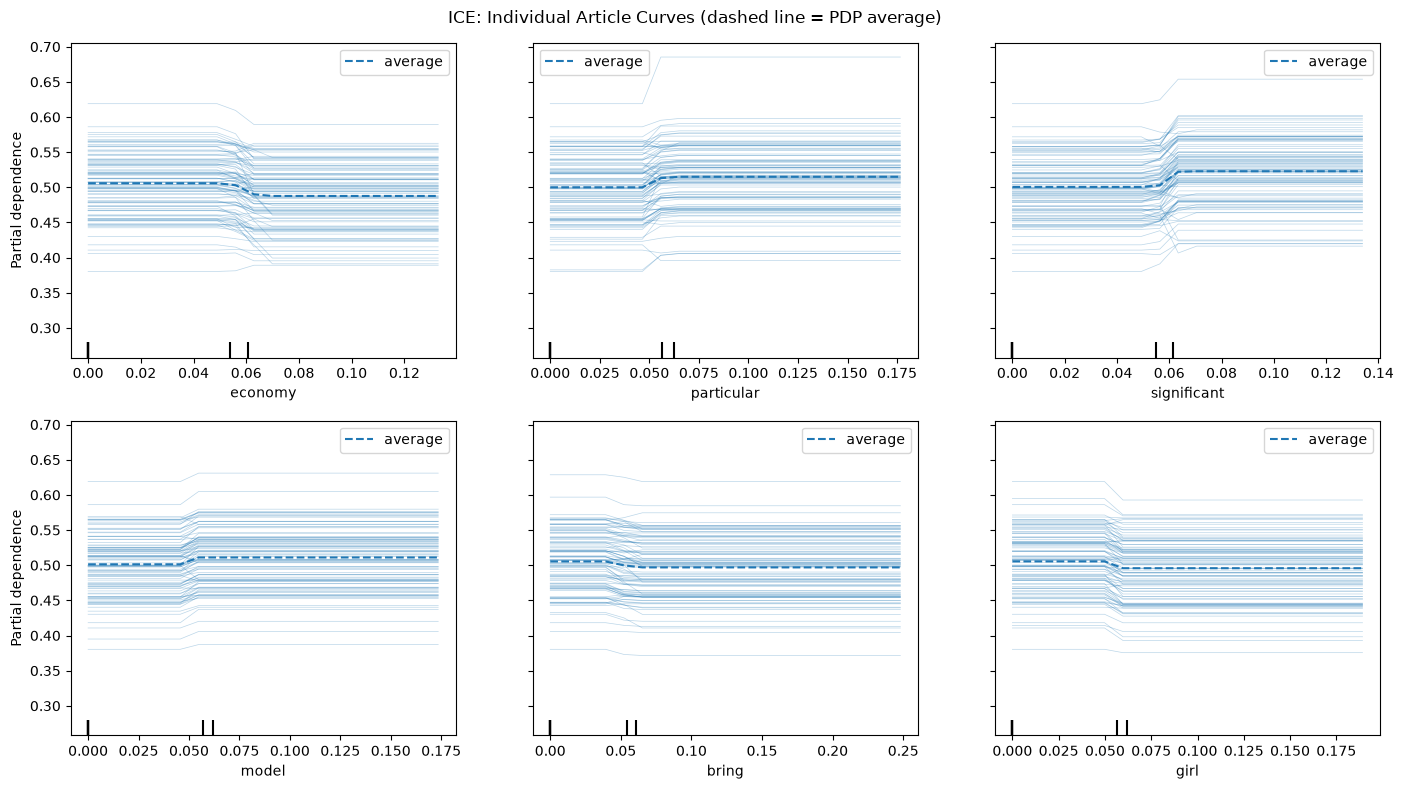

In [21]:
ice_display = PartialDependenceDisplay.from_estimator(
    xgb_model, X_sample,
    features=pdp_idx,
    feature_names=list(feature_names),
    kind="both",
    subsample=100,
    grid_resolution=20,
    percentiles=(0, 1),
    n_cols=3,
    random_state=RANDOM_STATE,
)
ice_display.figure_.set_size_inches(14, 8)
ice_display.figure_.suptitle("ICE: Individual Article Curves (dashed line = PDP average)")
plt.tight_layout()
plt.show()

Each thin line is one of 100 articles, and the dashed line is the PDP average. The lines start anywhere from about 0.38 to 0.62, because each prediction also depends on the article's other words. The average looks flat only because the vertical axis is more than ten times wider than in the PDP.

At the step, most lines move the same way as the average but by different amounts. One particular line jumps from about 0.62 to 0.69. Because the lines start at such different heights, the size of each move is hard to read here, so the centered version below shows it more clearly.

### 11.1 Centered ICE

Centered ICE shifts every line to start at 0, so each line shows only how much the predicted probability changes when the term is added to that article.

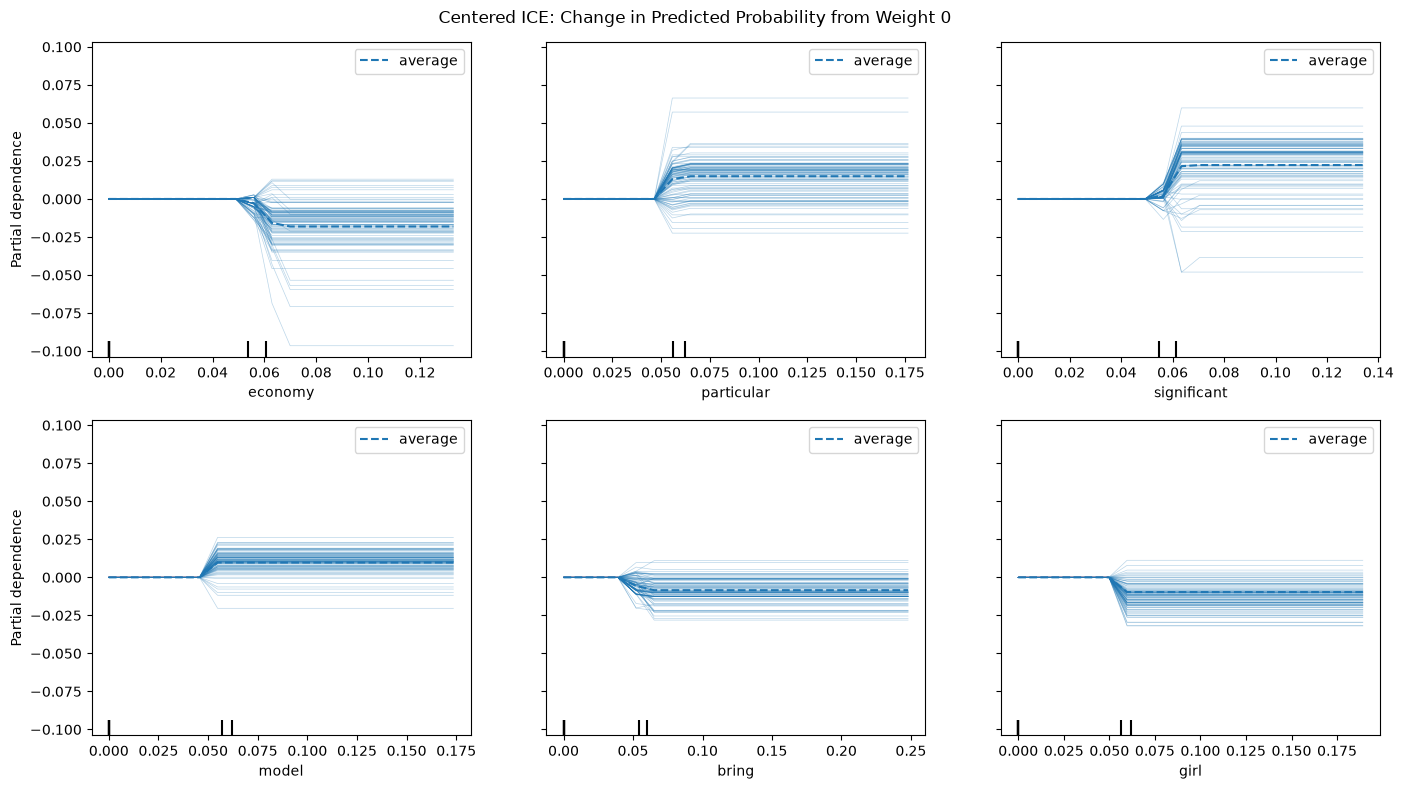

In [22]:
cice_display = PartialDependenceDisplay.from_estimator(
    xgb_model, X_sample,
    features=pdp_idx,
    feature_names=list(feature_names),
    kind="both",
    centered=True,
    subsample=100,
    grid_resolution=20,
    percentiles=(0, 1),
    n_cols=3,
    random_state=RANDOM_STATE,
)
cice_display.figure_.set_size_inches(14, 8)
cice_display.figure_.suptitle("Centered ICE: Change in Predicted Probability from Weight 0")
plt.tight_layout()
plt.show()

Every line is flat until the term goes from absent to present, at a weight of about 0.05.

For most terms, the lines mostly follow the average. For economy, the average drops by about 0.018, and most articles drop too, by up to about 0.10, though a few go up slightly. particular, model and girl behave the same way: one main direction, with a small share of articles going the other way. bring and girl are the most contained, with every article moving by less than about 3 points.

significant is the exception. Its average rises by about 0.022, and most articles rise by up to 0.06, but a smaller group drops, by up to about 0.05. A split like this suggests that significant's effect flips depending on another word in the article, which a boosted model can learn by combining terms within one tree.

The largest individual changes are about 10 percentage points for economy (down) and about 7 for particular (up), several times the average effect. So the PDP shows the typical direction, but single articles can move much further, and occasionally the other way.

## 12. Individual Decisions (LIME and SHAP)

So far we have looked at what drives the model overall. Now we look at single articles. First, SP-LIME picks a small set of representative articles. Then we look at three cases chosen by outcome: the fake article the model was most confident about, the fake article it missed most clearly, and the real article it most confidently flagged as fake.

In [23]:
explainer_lime = LimeTextExplainer(class_names=["real", "fake"], random_state=RANDOM_STATE)

def predict_proba_text(texts):
    # XGBoost was trained on dense arrays, so the TF-IDF output is converted to dense here as well
    return xgb_model.predict_proba(tfidf.transform(texts).toarray().astype(np.float32))

test_text = df.loc[y_test.index, "processed_text"].reset_index(drop=True)
y_true_arr = y_test.reset_index(drop=True).to_numpy()
y_pred_arr = np.asarray(y_pred)
proba_fake = xgb_model.predict_proba(X_test_dense)[:, 1]

tp = np.where((y_true_arr == 1) & (y_pred_arr == 1))[0]
fn = np.where((y_true_arr == 1) & (y_pred_arr == 0))[0]
fp = np.where((y_true_arr == 0) & (y_pred_arr == 1))[0]

cases = {
    "True Positive (fake, caught)":      tp[np.argmax(proba_fake[tp])],
    "False Negative (fake, missed)":     fn[np.argmin(proba_fake[fn])],
    "False Positive (real, flagged)":    fp[np.argmax(proba_fake[fp])],
}

### 12.1 SP-LIME: Choosing Representative Articles

Instead of picking articles by hand, SP-LIME (submodular pick) explains 200 random test articles and picks the 5 whose explanations together cover the most words with the least repetition. It does not look at the label or category, so we check those afterwards.

In [24]:
N_CANDIDATES = 200
N_PICKS = 5

rng_sp = np.random.RandomState(RANDOM_STATE)
cand_idx = rng_sp.choice(len(test_text), size=N_CANDIDATES, replace=False)
cand_text = test_text.iloc[cand_idx].tolist()

sp = SubmodularPick(
    explainer_lime, cand_text, predict_proba_text,
    method="full",
    num_exps_desired=N_PICKS,
    num_features=7,
    num_samples=1000,
    top_labels=None          # explain the fake class (label 1) for every article
)
sp_idx = cand_idx[sp.V]      # positions of the picked articles in the test set

In [25]:
def outcome(i):
    t, p = int(y_true_arr[i]), int(y_pred_arr[i])
    return {(1, 1): "TP (fake, caught)", (1, 0): "FN (fake, missed)",
            (0, 1): "FP (real, flagged)", (0, 0): "TN (real, correct)"}[(t, p)]

sp_table = pd.DataFrame({
    "category": [df.loc[y_test.index[i], "category"] for i in sp_idx],
    "true_label": ["fake" if y_true_arr[i] == 1 else "real" for i in sp_idx],
    "P(fake)": [round(float(proba_fake[i]), 3) for i in sp_idx],
    "outcome": [outcome(i) for i in sp_idx],
})
display(sp_table)

,category,true_label,P(fake),outcome
0,Technology,real,0.545,"FP (real, flagged)"
1,Science,fake,0.543,"TP (fake, caught)"
2,Science,fake,0.444,"FN (fake, missed)"
3,Science,real,0.554,"FP (real, flagged)"
4,Politics,fake,0.566,"TP (fake, caught)"


SP-LIME pick 1 | P(fake) = 0.545


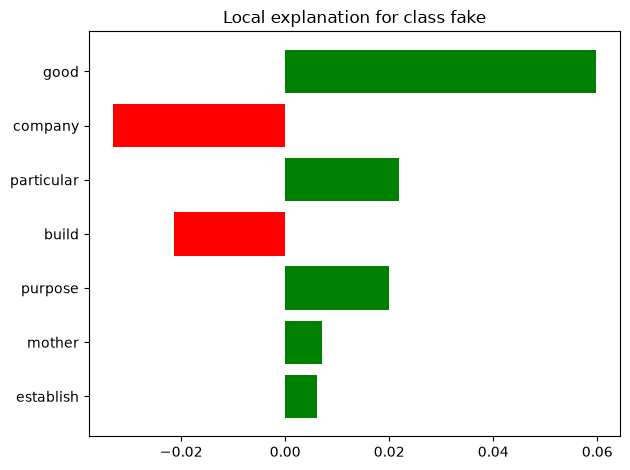

SP-LIME pick 2 | P(fake) = 0.543


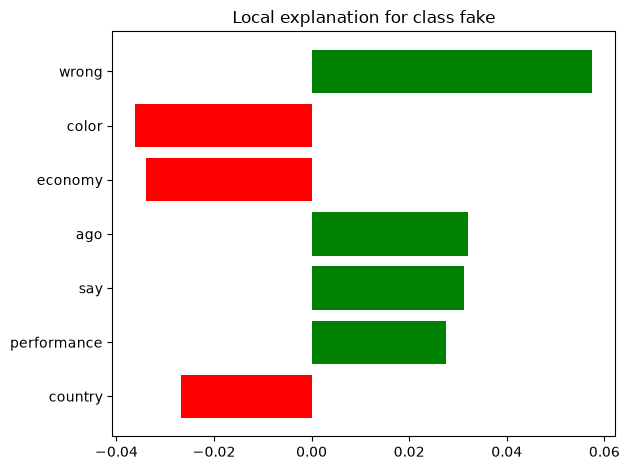

SP-LIME pick 3 | P(fake) = 0.444


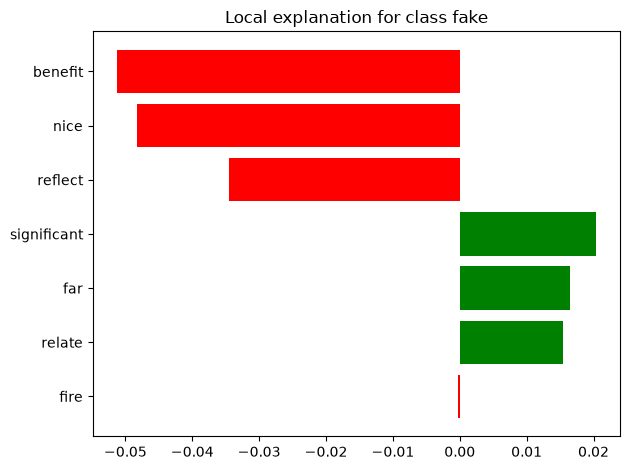

SP-LIME pick 4 | P(fake) = 0.554


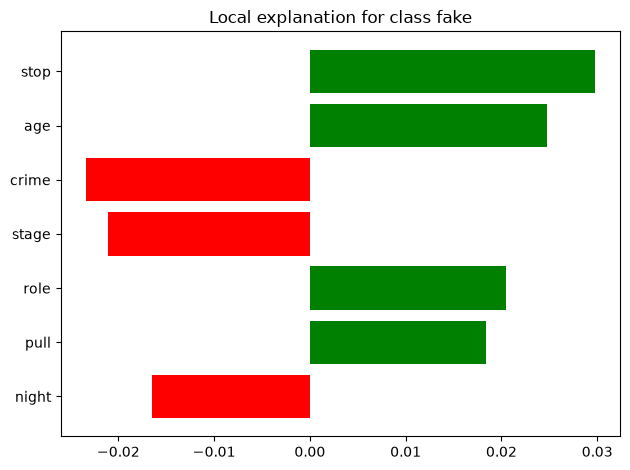

SP-LIME pick 5 | P(fake) = 0.566


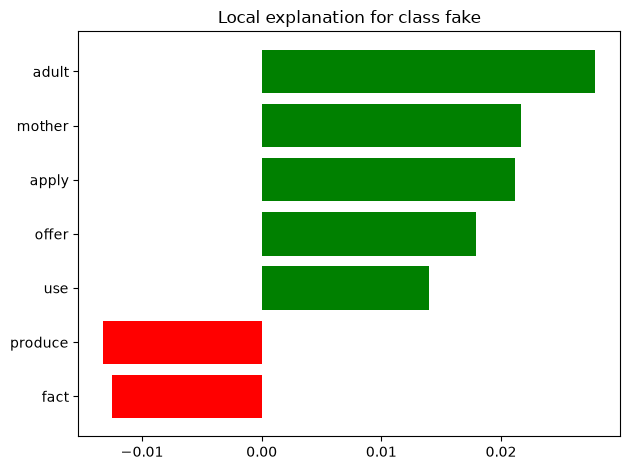

In [26]:
for rank, (exp, i) in enumerate(zip(sp.sp_explanations, sp_idx), start=1):
    print(f"SP-LIME pick {rank} | P(fake) = {proba_fake[i]:.3f}")
    exp.as_pyplot_figure(label=1)
    plt.tight_layout()
    plt.show()

The five picks are three Science articles, one Technology and one Politics, with three fake and two real. This mix is chance, since SP-LIME only looks at words. All five scores are between 0.444 and 0.566, so the model was unsure about every one.

**Wrongly flagged real articles (picks 1 and 4).** In pick 1, good alone pushes toward fake by 0.060, the largest bar in any pick. With particular, purpose, mother and establish, the fake side (about 0.12) beats company and build (about 0.05). In pick 4, stop, age, role and pull (about 0.09) beat crime, stage and night (about 0.06).

**Caught fake articles (picks 2 and 5).** In pick 2, wrong (0.058) leads ago, say and performance (about 0.15 in total) against color, economy and country (about 0.10). In pick 5, adult, mother, apply, offer and use (about 0.10) easily beat produce and fact (about 0.03).

**Missed fake article (pick 3, 0.444).** benefit, nice and reflect pull toward real (about 0.13), far more than significant, far and relate push toward fake (about 0.05).

Only mother appears in more than one pick, pushing toward fake both times. The words that also appear in the global SHAP results or the baseline (good, particular, wrong, significant, far and mother toward fake; economy and reflect toward real) all push the same way as there. The rest are ordinary words that appear in no global result.

### 12.2 LIME: Three Cases by Outcome

LIME removes words from one article and watches how the predicted probability changes. Positive weights push toward fake, negative toward real.

True Positive (fake, caught) | P(fake) = 0.678


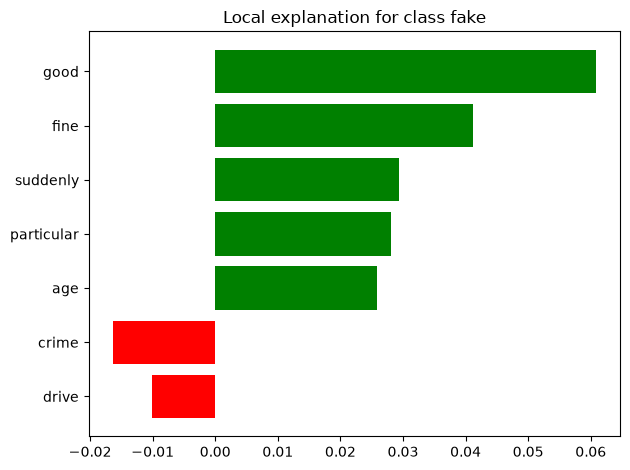

False Negative (fake, missed) | P(fake) = 0.298


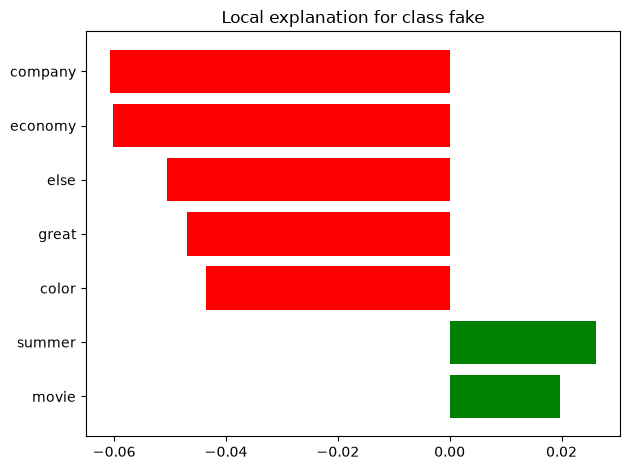

False Positive (real, flagged) | P(fake) = 0.688


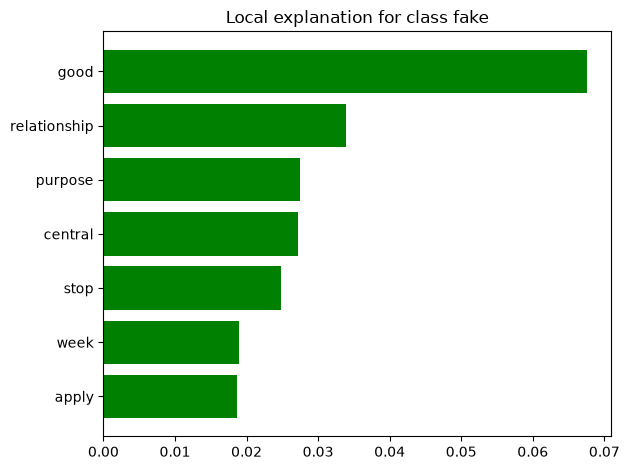

In [27]:
for name, i in cases.items():
    exp = explainer_lime.explain_instance(
        test_text.iloc[i], predict_proba_text,
        num_features=7, num_samples=1000, labels=(1,)
    )
    print(f"{name} | P(fake) = {proba_fake[i]:.3f}")
    exp.as_pyplot_figure(label=1)
    plt.tight_layout()
    plt.show()

These are the most extreme articles in each group.

**True Positive (P(fake) = 0.678).** good (0.061) and fine (0.041) push hardest toward fake, followed by suddenly, particular and age. crime and drive push toward real (0.016 and 0.010).

**False Negative (P(fake) = 0.298).** company and economy pull toward real by about 0.06 each, joined by else, great and color. summer and movie push toward fake but are too weak. None of these words says anything about whether the reporting is trustworthy.

**False Positive (P(fake) = 0.688).** All seven words push toward fake, led by good (0.068), relationship and purpose. This is the highest probability of fake in the whole test set, and it belongs to a real article.

The caught fake article and the flagged real one are both led by good, and the real one scores higher (0.688 vs 0.678). So the model gives the same main reason for a correct flag and a wrong one, and its confidence cannot tell them apart.

### 12.3 SHAP Waterfall (the missed fake article)

LIME approximates the model around one article, while SHAP splits the model's own output into exact contributions. Here SHAP explains the missed fake article from 12.2, so the two methods can be compared on the same case. Values are in log-odds.

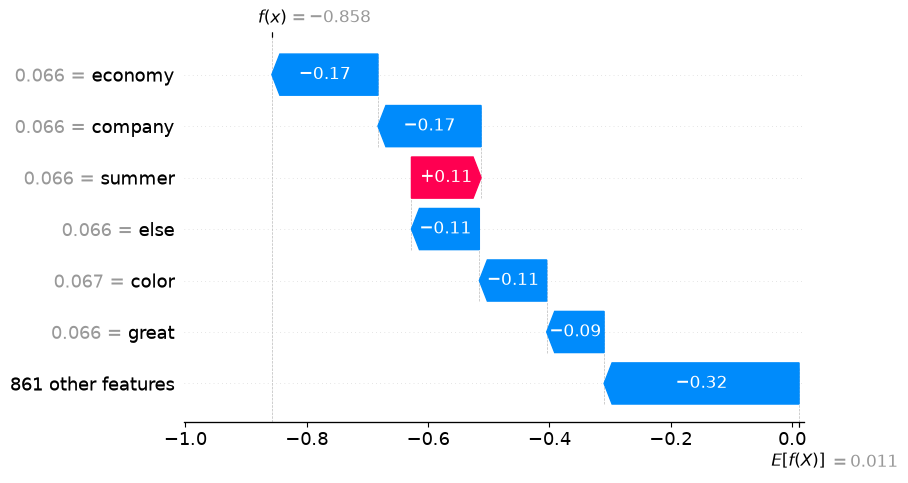

In [28]:
fn_idx = cases["False Negative (fake, missed)"]
x_fn = X_test_dense[fn_idx:fn_idx + 1]

sv_fn = explainer_shap.shap_values(x_fn, check_additivity=False)
if isinstance(sv_fn, list):
    sv_fn_fake = sv_fn[1]
elif sv_fn.ndim == 3:
    sv_fn_fake = sv_fn[:, :, 1]
else:
    sv_fn_fake = sv_fn

shap.plots.waterfall(
    shap.Explanation(
        values=sv_fn_fake[0], base_values=base_value,
        data=x_fn[0], feature_names=list(feature_names)
    ),
    max_display=7
)

The waterfall starts at 0.011 log-odds, the model’s average output (a probability of about 0.503), and ends at −0.858 (a probability of 0.298) for this missed fake article.

economy and company are the largest terms, at −0.17 log-odds each (about 4 percentage points), followed by else and color (−0.11 each) and great (−0.09). summer is the only term pushing toward fake (+0.11). Together these six add −0.54, while the 861 other terms add −0.32. So a handful of words matters more in total here, though the other terms still form the largest single bar.

SHAP and LIME agree very closely. All six of SHAP’s terms appear in LIME’s seven with the same direction: company, economy, else, great and color toward real, and summer toward fake. Only movie appears in LIME and not in SHAP. For this article, LIME gives a reliable picture of what drives the prediction.

## 13. Summary

XGBoost catches 53% of fake articles (recall 0.5281), with an accuracy of 0.511 and a ROC AUC of 0.510, so it barely separates fake from real. It misses 24 fewer fake articles than the Logistic Regression baseline (recall 0.5162), the highest recall of any model so far, but its accuracy is no better than LightGBM's or the Random Forest's, and gains this small are within the normal variation of one test split. Training recall (0.7817) is much higher than test recall, so it still memorises part of the training data.

The explanation methods agree that no word matters much:
- **PFI:** only role and girl drop recall by more than any random term, and only just (at most 0.006, about 11 articles). The other top terms cannot be told apart from noise.
- **TreeSHAP:** the top term, significant, moves the output by about 0.6 percentage points on average.
- **PDP and ICE:** each term shifts the average probability by at most about 2 points, though single articles can move up to about 10 points, and for significant a smaller group of articles moves the opposite way.
- **LIME:** predictions come from several ordinary words. The highest probability of fake in the whole test set belongs to a real article, and it rests on the same main word, good, as the most confident correct flag.
- **SHAP waterfall:** for the missed fake article, SHAP and LIME agree very closely: all six of SHAP's top words appear in LIME's list, with economy and company leading.

Where SHAP, PDP, LIME and the baseline share a term, they agree on its direction: significant, particular, good and wrong lean toward fake, and economy and reflect toward real. PFI and SHAP otherwise rank terms differently, because PFI measures the effect on catching fake articles rather than the average effect on the output.

Overall, XGBoost does no better than the baseline, which confirms that the text carries very little signal.